# Laboratorio 14: Especificidad, sensibilidad y curvas ROC

**Mateo Caballero** - Aprendizaje Estadístico - semestre 2026-2

Enunciado original: `semestre2026-2/Laboratorios/Laboratorio_14_EspecificidadSensibilidadROC.ipynb`

El enunciado no numera las actividades. El desarrollo sigue su orden en cinco puntos: especificidad,
sensibilidad, curva ROC, frontera óptima y la pregunta final sobre distribuciones muy juntas.

Se conserva el notebook original y las celdas propias empiezan con `# [Añadido]`. Solo hay dos
intervenciones sobre su ejecución:

- Se fija la semilla antes de generar las muestras, porque el original no lo hace.
- En la penúltima celda se quitan los caracteres `¿¡` y la sangría, que impedían ejecutarla. Está marcada
  `# [Modificado]`.


[Sensibilidad y Especificidad](https://es.wikipedia.org/wiki/Sensibilidad_y_especificidad)


*Sensiblidad*:  capacidad de la prueba para detectar un sujeto enfermo, en otras palabras, ¿Cual es la probabilidad de que el resultado sea postivo?.

Probabilidad de que la prueba indentifique como enfermo aquel que realmente esta:

$S = \frac{Verdadedor Positivos}{Total Enfermos}=\frac{VP}{VP+FN}$


*Especificidad*: Indentifiar como sanos a los que realmente lo son.

$E = \frac{Verdadedor Negativos}{Total  de NO Enfermos}=\frac{VN}{VN+FP}$




In [1]:
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns
from scipy import stats
from scipy import optimize
from scipy.stats import norm

In [2]:
# [Añadido]
from sklearn.metrics import roc_auc_score, roc_curve

SEED = 42
np.random.seed(SEED)       # f1.rvs y f2.rvs usan el generador global de NumPy

In [3]:
def pdf(x, mean1 = 10, mean2=16, desv1=2, desv2=2):
  fig, ax = plt.subplots(1, 1)
  
  f1 = stats.norm(loc = mean1, scale = desv1)
  f2 = stats.norm(loc = mean2, scale = desv2)
  ax.plot(x, f1.pdf(x),'g-', lw = 3, alpha = 0.6, label='pdf 1')
  ax.plot(x, f2.pdf(x),'b-', lw = 3, alpha = 0.6, label='pdf 2')  
  ax.set_xlabel("x")
  ax.set_ylabel("PDF(X)")
  return "Done", f1, f2

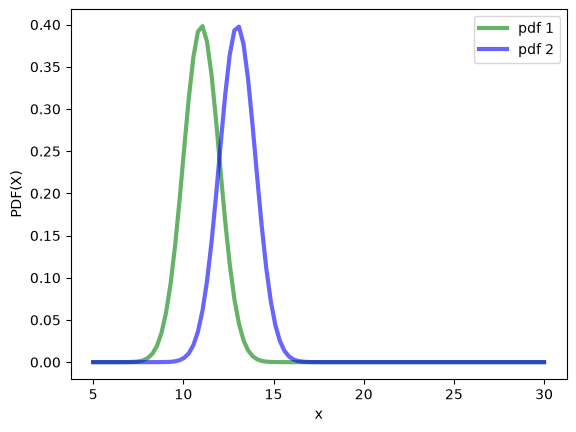

In [4]:
x=np.linspace(5, 30,100)
_, f1, f2 = pdf(x, mean1 = 11, mean2 = 13, desv1 = 1, desv2 = 1)
plt.legend()

### El modelo

Los sanos siguen $N(11,1)$ y los enfermos $N(13,1)$. La prueba es positiva si $x>b$, donde $b$ es la
frontera. Como se conocen las distribuciones, cada cantidad de la muestra se puede comparar con su valor
exacto:

$$E(b)=\Phi(b-11),\qquad S(b)=1-\Phi(b-13).$$

In [5]:
random_1 = f1.rvs(1000)
random_2 = f2.rvs(1000)


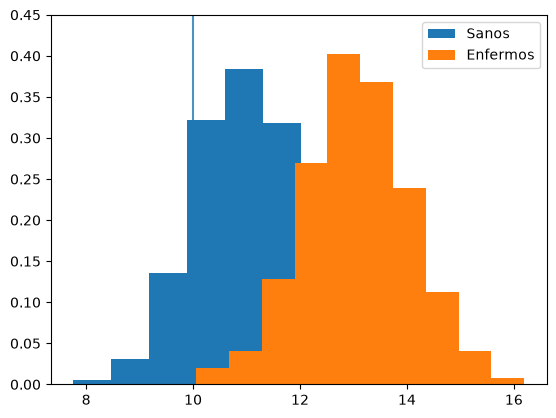

In [6]:
boundary = 10
plt.figure()
plt.hist(random_1, density=True, label="Sanos")
#plt.plot(x, f1.pdf(x))
plt.hist(random_2, density=True, label="Enfermos")
plt.vlines(boundary, 0, 1, alpha=0.8)
#plt.plot(x, f2.pdf(x))
plt.ylim(0,0.45)
plt.legend()
plt.show()

In [7]:
# [Añadido]
for nombre, muestra in (("sanos", random_1), ("enfermos", random_2)):
    print(f"{nombre:9s} n = {len(muestra)} | media = {muestra.mean():.3f} | desviación = {muestra.std(ddof=1):.3f} "
          f"| entre {muestra.min():.2f} y {muestra.max():.2f}")

sanos     n = 1000 | media = 11.019 | desviación = 0.979 | entre 7.76 y 14.85
enfermos  n = 1000 | media = 13.071 | desviación = 0.997 | entre 10.06 y 16.19


Las muestras reproducen el modelo (medias 11.019 y 13.071, desviaciones 0.979 y 0.997). Se traslapan entre
10.06 y 14.85, así que ninguna frontera las separa sin errores. La de $b=10$ deja a la derecha a todos los
enfermos y también a la mayoría de los sanos.

Especificidad:
Probabilidad de indentifiar como sanos a los que realmente lo son.


$E = \frac{VN}{VN+FP}$

In [8]:
VN = (random_1<boundary).sum()
FP = (random_1>boundary).sum()
E = VN/(VN+FP)
E

np.float64(0.147)

### Punto 1. Especificidad

> Probabilidad de indentifiar como sanos a los que realmente lo son.

In [9]:
# [Añadido]
def wilson(k, n, z=1.96):
    """Intervalo del 95 % para una proporción."""
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - mitad, centro + mitad


li, ls = wilson(VN, VN + FP)
print(f"VN = {VN}, FP = {FP} | E = {E:.3f} | IC 95 % = [{li:.3f}, {ls:.3f}]")
print(f"teoría: P(x < {boundary} | sano) = {f1.cdf(boundary):.4f}")

VN = 147, FP = 853 | E = 0.147 | IC 95 % = [0.126, 0.170]
teoría: P(x < 10 | sano) = 0.1587


**$E=0.147$: la prueba reconoce a 147 de los 1 000 sanos.** Los otros 853 son falsos positivos. El valor
teórico, 0.1587, está dentro del intervalo del 95 % ([0.126, 0.170]), de modo que la diferencia es
compatible con el muestreo.

Sensibilidad

Probabilidad de que la prueba indentifique como enfermo aquel que realmente esta

$S = \frac{VP}{VP+FN}$

In [10]:
VP = (random_2>boundary).sum()
FN = (random_2<boundary).sum()
S = VP/(VP+FN)
S

np.float64(1.0)

### Punto 2. Sensibilidad

> Probabilidad de que la prueba indentifique como enfermo aquel que realmente esta

In [11]:
# [Añadido]
li, ls = wilson(VP, VP + FN)
print(f"VP = {VP}, FN = {FN} | S = {S:.3f} | IC 95 % = [{li:.3f}, {ls:.3f}]")
print(f"teoría: P(x > {boundary} | enfermo) = {f2.sf(boundary):.4f}")

print("\nMatriz de confusión:")
print(pd.DataFrame([[VN, FP], [FN, VP]], index=["sano", "enfermo"],
                   columns=["prueba negativa", "prueba positiva"]).to_string())
print(f"P(prueba positiva), sin condicionar, con mitad y mitad = {(VP + FP) / (VP + FN + VN + FP):.4f}")

VP = 1000, FN = 0 | S = 1.000 | IC 95 % = [0.996, 1.000]
teoría: P(x > 10 | enfermo) = 0.9987

Matriz de confusión:
         prueba negativa  prueba positiva
sano                 147              853
enfermo                0             1000
P(prueba positiva), sin condicionar, con mitad y mitad = 0.9265


**$S=1.000$: la prueba detecta a los 1 000 enfermos.** Eso no la vuelve perfecta. El valor teórico es
0.9987, y con cero falsos negativos en 1 000 casos el intervalo del 95 % todavía baja hasta 0.996.

La introducción del enunciado también describe $S$ como "la probabilidad de que el resultado sea
positivo". Falta la condición: es $P(+\mid\text{enfermo})$. Sin condicionar, con mitad de sanos y mitad de
enfermos, la probabilidad de un positivo es 0.9265, que es otra cantidad.

En $b=10$ la prueba casi no descarta enfermos, a cambio de alarmar al 85.3 % de los sanos.

Para diferentes fronteras como es la sensiblidad como funcion de la especificidad 1-E. 
Curvas Roc https://es.wikipedia.org/wiki/Curva_ROC

In [12]:
boundary_=np.linspace(2,20,100)
E_=[]
S_=[]
for b in boundary_:
  VN = (random_1<b).sum()
  FP = (random_1>b).sum()
  E = VN/(VN+FP)
  E_.append(E)

  VP = (random_2>b).sum()
  FN = (random_2<b).sum()
  S = VP/(VP+FN)  
  S_.append(S)

Text(0, 0.5, 'S')

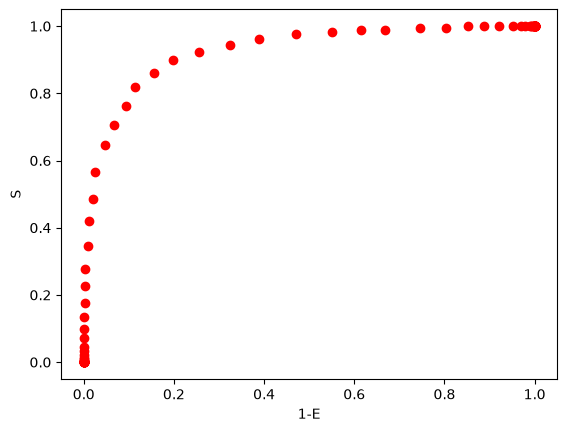

In [13]:
plt.plot( (1-np.array(E_)), np.array(S_),"ro")
plt.xlabel("1-E")
plt.ylabel("S")


### Punto 3. Curva ROC

> Para diferentes fronteras como es la sensiblidad como funcion de la especificidad 1-E.

In [14]:
# [Añadido]
E_np, S_np = np.array(E_), np.array(S_)
print(" frontera      E       S     1-E")
for b in (9, 10, 11, 12, 13, 14, 15):
    e, s = np.mean(random_1 < b), np.mean(random_2 > b)
    print(f"{b:9.1f} {e:7.3f} {s:7.3f} {1 - e:7.3f}")
print("\nal subir la frontera, E nunca baja:", np.all(np.diff(E_np) >= 0),
      "| S nunca sube:", np.all(np.diff(S_np) <= 0))

etiquetas = np.r_[np.zeros(len(random_1)), np.ones(len(random_2))]
valores = np.r_[random_1, random_2]

d_prima = (f2.mean() - f1.mean()) / f1.std()
auc_rejilla = np.trapezoid(S_np[::-1], 1 - E_np[::-1])
auc_pares = np.mean(random_2[:, None] > random_1[None, :])
print(f"\nAUC, trapecios sobre las 100 fronteras = {auc_rejilla:.4f}")
print(f"AUC, pares con enfermo > sano          = {auc_pares:.4f}")
print(f"AUC, scikit-learn                      = {roc_auc_score(etiquetas, valores):.4f}")
print(f"AUC, teoría Phi(d'/raiz(2))            = {norm.cdf(d_prima / np.sqrt(2)):.4f}")

rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    v = np.r_[rng.choice(random_1, len(random_1)), rng.choice(random_2, len(random_2))]
    boot.append(roc_auc_score(etiquetas, v))
li, ls = np.percentile(boot, [2.5, 97.5])
print(f"IC 95 % bootstrap del AUC = [{li:.4f}, {ls:.4f}]")

 frontera      E       S     1-E
      9.0   0.017   1.000   0.983
     10.0   0.147   1.000   0.853
     11.0   0.490   0.982   0.510
     12.0   0.845   0.861   0.155
     13.0   0.976   0.523   0.024
     14.0   0.998   0.176   0.002
     15.0   1.000   0.030   0.000

al subir la frontera, E nunca baja: True | S nunca sube: True

AUC, trapecios sobre las 100 fronteras = 0.9267
AUC, pares con enfermo > sano          = 0.9278
AUC, scikit-learn                      = 0.9278
AUC, teoría Phi(d'/raiz(2))            = 0.9214
IC 95 % bootstrap del AUC = [0.9165, 0.9378]


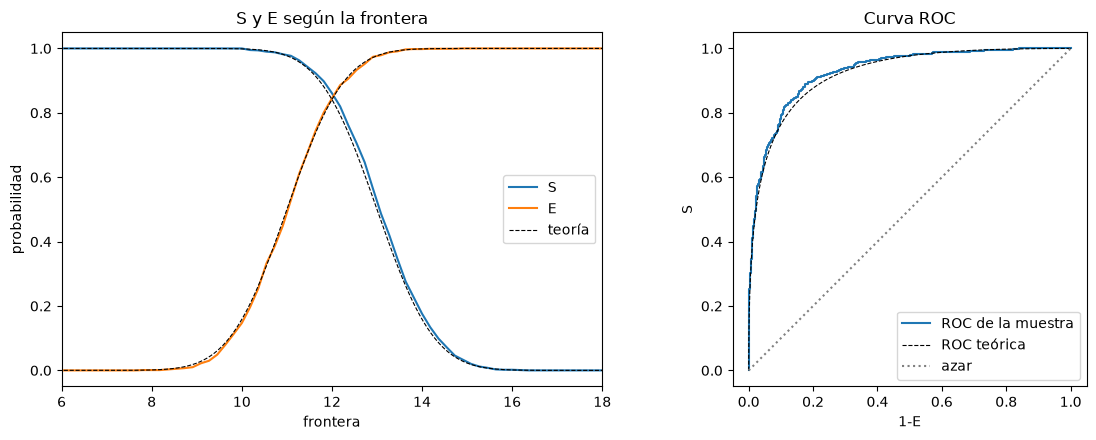

In [15]:
# [Añadido]
t = np.linspace(2, 22, 1000)
fp_emp, vp_emp, _ = roc_curve(etiquetas, valores)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(boundary_, S_np, label="S")
axes[0].plot(boundary_, E_np, label="E")
axes[0].plot(t, f2.sf(t), "k--", lw=0.8, label="teoría")
axes[0].plot(t, f1.cdf(t), "k--", lw=0.8)
axes[0].set(xlim=(6, 18), xlabel="frontera", ylabel="probabilidad", title="S y E según la frontera")
axes[0].legend()

axes[1].plot(fp_emp, vp_emp, label="ROC de la muestra")
axes[1].plot(f1.sf(t), f2.sf(t), "k--", lw=0.8, label="ROC teórica")
axes[1].plot([0, 1], [0, 1], color="gray", ls=":", label="azar")
axes[1].set(xlabel="1-E", ylabel="S", title="Curva ROC", aspect="equal")
axes[1].legend()
plt.tight_layout()
plt.show()

**$S$ crece con $1-E$: para detectar más enfermos hay que aceptar más falsos positivos.**

- Al subir la frontera $E$ nunca baja y $S$ nunca sube. Pasar de $b=10$ a $b=12$ lleva $E$ de 0.147 a
  0.845 y $S$ de 1.000 a 0.861.
- La curva sube muy rápido cerca del origen y luego se aplana. Al principio se ganan muchos verdaderos
  positivos por cada falso positivo, y al final casi ninguno.
- La curva queda muy por encima de la diagonal, que es clasificar al azar.

El área bajo la curva (AUC) resume todas las fronteras en un número: es la probabilidad de que un enfermo
al azar tenga un $x$ mayor que un sano al azar. Contando pares da 0.9278, lo mismo que scikit-learn. Con
solo las 100 fronteras los trapecios dan 0.9267. El valor teórico, 0.9214, está dentro del intervalo
bootstrap del 95 % ([0.9165, 0.9378]).

In [16]:
S_=np.array(S_)
E_=np.array(E_)

boptimoS=boundary_[S_==max(S_)]

Eoptimo=E_[S_==max(S_)]

In [17]:
boptimo=boptimoS[Eoptimo==max(Eoptimo)]

In [18]:
boptimo

array([10.])

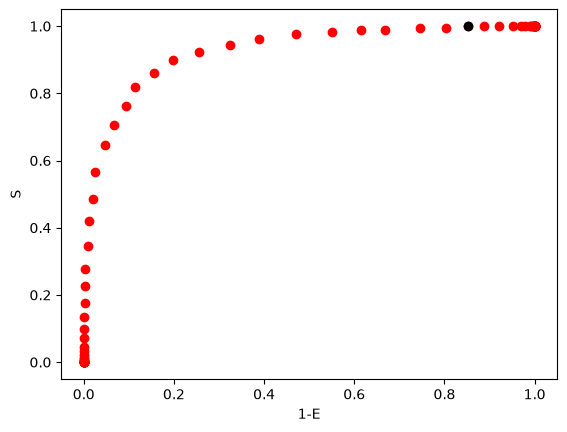

In [19]:
plt.plot( (1-E_),S_,"ro")
plt.xlabel("1-E")
plt.ylabel("S")
plt.plot((1-E_[boundary_==boptimo]),S_[boundary_==boptimo], "ko")

In [20]:
# [Modificado] se quitaron '¿¡' y la sangría, que impedían ejecutar la celda
(1-np.array(E_))

array([1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   , 1.   ,
       1.   , 1.   , 1.   , 1.   , 1.   , 0.999, 0.999, 0.999, 0.997,
       0.995, 0.993, 0.99 , 0.978, 0.97 , 0.951, 0.92 , 0.887, 0.853,
       0.804, 0.746, 0.668, 0.615, 0.551, 0.47 , 0.389, 0.324, 0.256,
       0.199, 0.155, 0.114, 0.094, 0.067, 0.048, 0.026, 0.021, 0.012,
       0.009, 0.003, 0.002, 0.002, 0.001, 0.001, 0.001, 0.001, 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
       0.   ])

### Punto 4. Frontera óptima

El código del enunciado toma la mayor sensibilidad y, entre las fronteras empatadas, la de mayor
especificidad. Se compara con otros dos criterios y con el óptimo teórico de Youden. Como
$J=S+E-1$, al derivar se obtiene $dJ/db=f_1(b)-f_2(b)$: el máximo está donde se cruzan las dos
densidades, $b=12$.

In [21]:
# [Añadido]
b_enun = float(boptimo[0])
print(f"frontera del enunciado = {b_enun:.4f} | mínimo de los enfermos = {random_2.min():.4f} "
      f"| paso de la rejilla = {boundary_[1] - boundary_[0]:.4f}")

youden = np.argmax(S_np + E_np - 1)
cercano = np.argmin((1 - S_np) ** 2 + (1 - E_np) ** 2)
candidatas = {"enunciado (máx S, luego máx E)": b_enun,
              "Youden (máx S + E - 1)": boundary_[youden],
              "más cercana a (0, 1)": boundary_[cercano],
              "teórica (cruce de las pdf)": (f1.mean() + f2.mean()) / 2}


def metricas(b, sanos, enfermos):
    s, e = np.mean(enfermos > b), np.mean(sanos < b)
    return s, e, s + e - 1


# Muestra nueva, que no se usó para escoger ninguna frontera
rng = np.random.default_rng(SEED + 1)
sanos_n, enfermos_n = f1.rvs(100000, random_state=rng), f2.rvs(100000, random_state=rng)
print(f"\n{'criterio':32s} {'b':>7} | {'S':>6} {'E':>6} {'J':>6} {'FN':>4} {'FP':>4} | muestra nueva: S, E, J")
for nombre, b in candidatas.items():
    s, e, j = metricas(b, random_1, random_2)
    sn, en, jn = metricas(b, sanos_n, enfermos_n)
    print(f"{nombre:32s} {b:7.3f} | {s:6.3f} {e:6.3f} {j:6.3f} {np.sum(random_2 < b):4d} "
          f"{np.sum(random_1 > b):4d} | {sn:.4f}, {en:.4f}, {jn:.4f}")

frontera del enunciado = 10.0000 | mínimo de los enfermos = 10.0596 | paso de la rejilla = 0.1818

criterio                               b |      S      E      J   FN   FP | muestra nueva: S, E, J
enunciado (máx S, luego máx E)    10.000 |  1.000  0.147  0.147    0  853 | 0.9986, 0.1586, 0.1572
Youden (máx S + E - 1)            12.000 |  0.861  0.845  0.706  139  155 | 0.8409, 0.8419, 0.6828
más cercana a (0, 1)              12.000 |  0.861  0.845  0.706  139  155 | 0.8409, 0.8419, 0.6828
teórica (cruce de las pdf)        12.000 |  0.861  0.845  0.706  139  155 | 0.8409, 0.8419, 0.6828


In [22]:
# [Añadido]
# Qué tan estable es cada criterio: 2000 muestras nuevas para cada tamaño
REP = 2000
rng = np.random.default_rng(SEED)
for n in (100, 1000, 10000):
    b_s, b_j, b_c, empates = [], [], [], 0
    for _ in range(REP):
        s1 = np.sort(f1.rvs(n, random_state=rng))
        s2 = np.sort(f2.rvs(n, random_state=rng))
        E_b = np.searchsorted(s1, boundary_) / n
        S_b = 1 - np.searchsorted(s2, boundary_) / n
        S_max = S_b == S_b.max()
        empates += np.sum(S_max & (E_b == E_b[S_max].max())) > 1
        b_s.append(boundary_[S_max][-1])                # máx S y, entre esas, máx E
        b_j.append(boundary_[np.argmax(S_b + E_b - 1)])
        u = np.sort(np.r_[s1, s2])                      # Youden sin rejilla: cada dato es un corte posible
        b_c.append(u[np.argmax(np.searchsorted(s1, u, 'right') - np.searchsorted(s2, u, 'right'))])
    print(f"n = {n:5d}: enunciado {np.mean(b_s):6.3f} +- {np.std(b_s):.3f} | Youden {np.mean(b_j):6.3f} +- {np.std(b_j):.3f} "
          f"| boptimo con más de un valor: {empates / REP:.1%}")
    print(f"           Youden sin rejilla {np.mean(b_c):6.3f} +- {np.std(b_c):.3f}")
fp_u, vp_u, cortes_u = roc_curve(etiquetas, valores, drop_intermediate=False)
print(f"en la muestra del enunciado, Youden sin rejilla: b = {cortes_u[np.argmax(vp_u - fp_u)]:.3f}")

n =   100: enunciado 10.408 +- 0.435 | Youden 11.974 +- 0.219 | boptimo con más de un valor: 1.8%
           Youden sin rejilla 11.945 +- 0.213
n =  1000: enunciado  9.664 +- 0.362 | Youden 12.004 +- 0.109 | boptimo con más de un valor: 0.2%
           Youden sin rejilla 11.996 +- 0.101
n = 10000: enunciado  9.054 +- 0.316 | Youden 12.000 +- 0.014 | boptimo con más de un valor: 0.1%
           Youden sin rejilla 11.998 +- 0.047
en la muestra del enunciado, Youden sin rejilla: b = 11.894


ValueError: operands could not be broadcast together with shapes (100,) (2,) 


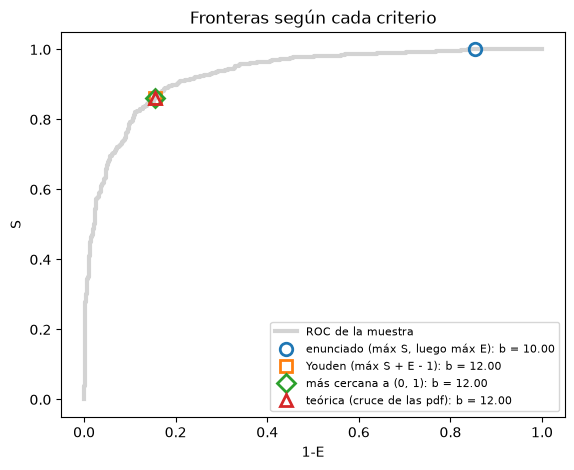

In [23]:
# [Añadido]
# Qué le pasa a la última gráfica del enunciado si boptimo trae dos valores
try:
    boundary_ == boundary_[:2]
except ValueError as error:
    print("ValueError:", error)

plt.figure(figsize=(6.5, 5))
plt.plot(fp_emp, vp_emp, color="lightgray", lw=3, label="ROC de la muestra")
for (nombre, b), marca in zip(candidatas.items(), "osD^"):
    s, e, _ = metricas(b, random_1, random_2)
    plt.plot(1 - e, s, marca, ms=9, mfc="none", mew=2, label=f"{nombre}: b = {b:.2f}")
plt.xlabel("1-E")
plt.ylabel("S")
plt.title("Fronteras según cada criterio")
plt.legend(fontsize=8)
plt.show()

**La frontera del enunciado es $b=10$. Solo tiene sentido si un falso negativo es inaceptable.**

| Criterio | $b$ | $S$ | $E$ | FN | FP |
|---|---|---|---|---|---|
| Enunciado | 10 | 1.000 | 0.147 | 0 | 853 |
| Youden, distancia a (0, 1) y teoría | 12 | 0.861 | 0.845 | 139 | 155 |

- El criterio del enunciado elige la última frontera de la rejilla por debajo del enfermo con menor $x$
  (10.0596). Depende de un solo dato extremo.
- Por eso no converge: en promedio da 10.408 con $n=100$, 9.664 con $n=1000$ y 9.054 con $n=10000$. A más
  datos aparecen enfermos con $x$ más bajo. En la población $S<1$ para cualquier $b$ finito, de modo que
  ese óptimo no existe.
- Su $S=1$ tampoco se mantiene en una muestra nueva, donde baja a 0.9986.
- Youden sí converge a 12. Para medirlo hay que quitar la rejilla, que tiene un paso de 0.1818 y contiene
  justo al 12, y por eso aparenta más precisión de la que hay: con $n=10000$ su desviación es 0.014, y sin
  rejilla es 0.047. Por lo mismo, que tres criterios den exactamente 12 en la tabla se debe en parte a la
  rejilla. Sin ella, Youden da 11.894 en esta muestra.
- El código puede devolver más de un valor en `boptimo` (1.8 % de las muestras con $n=100$). En ese caso
  la comparación `boundary_==boptimo` de su última gráfica produce un `ValueError`.

Cuál usar depende del costo de cada error. Para un tamizaje de una enfermedad grave conviene $S$ alta,
fijando un mínimo explícito (por ejemplo 0.95) en lugar de perseguir $S=1$. Si los dos errores cuestan
igual y los grupos son del mismo tamaño, conviene $b=12$.

In [24]:
#¿Que pasa si las distribuciones estan muy juntas?

### Punto 5. ¿Qué pasa si las distribuciones están muy juntas?

Se deja fija la media de los sanos, se acerca la de los enfermos y se mantiene $\sigma=1$. Con varianzas
iguales y separación $\Delta$, el área común de las densidades es $2\Phi(-\Delta/2)$ y
$AUC=\Phi(\Delta/\sqrt2)$.

In [25]:
# [Añadido]
separaciones = [0, 0.1, 0.25, 0.5, 1, 2, 3, 4]
rng = np.random.default_rng(SEED)
z1, z2 = rng.standard_normal(100000), rng.standard_normal(100000)     # mismo ruido en todos los casos
etiq = np.r_[np.zeros(len(z1)), np.ones(len(z2))]

print(f"muestra simulada: {len(z1)} por grupo")
print(f"{'separación':>10} {'traslape':>9} {'AUC teo.':>9} {'AUC sim.':>9} {'S=E en el cruce':>16} {'J máx':>7} {'E si S=0.95':>12}")
for delta in separaciones:
    auc = roc_auc_score(etiq, np.r_[11 + z1, 11 + delta + z2])
    print(f"{delta:10.2f} {2 * norm.cdf(-delta / 2):9.3f} {norm.cdf(delta / np.sqrt(2)):9.3f} {auc:9.3f} "
          f"{norm.cdf(delta / 2):16.3f} {2 * norm.cdf(delta / 2) - 1:7.3f} {norm.cdf(delta + norm.ppf(0.05)):12.3f}")

muestra simulada: 100000 por grupo
separación  traslape  AUC teo.  AUC sim.  S=E en el cruce   J máx  E si S=0.95
      0.00     1.000     0.500     0.502            0.500   0.000        0.050
      0.10     0.960     0.528     0.530            0.520   0.040        0.061
      0.25     0.901     0.570     0.572            0.550   0.099        0.082
      0.50     0.803     0.638     0.640            0.599   0.197        0.126
      1.00     0.617     0.760     0.761            0.691   0.383        0.260
      2.00     0.317     0.921     0.922            0.841   0.683        0.639
      3.00     0.134     0.983     0.983            0.933   0.866        0.912
      4.00     0.046     0.998     0.998            0.977   0.954        0.991


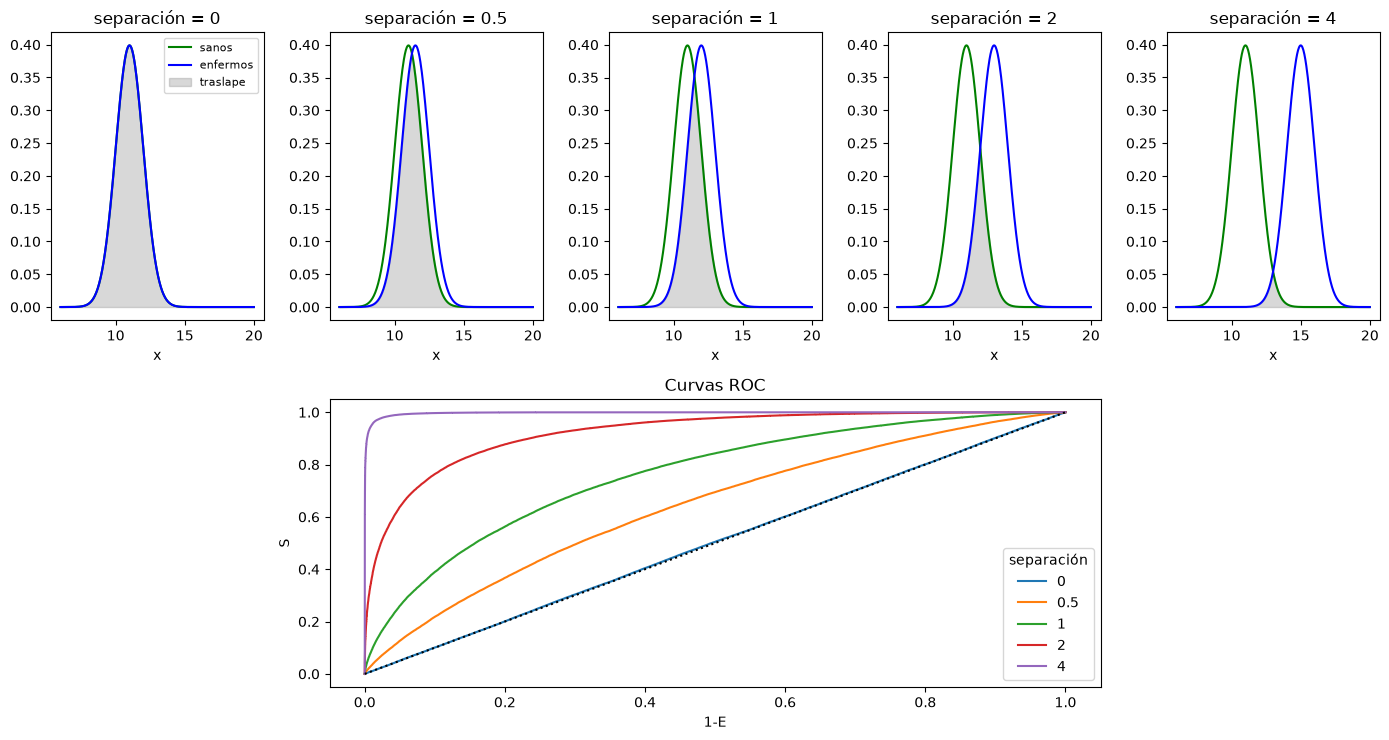

In [26]:
# [Añadido]
casos = [0, 0.5, 1, 2, 4]
xx = np.linspace(6, 20, 400)
fig = plt.figure(figsize=(14, 7.5))
rejilla = fig.add_gridspec(2, len(casos))
ax_roc = fig.add_subplot(rejilla[1, 1:4])
for k, delta in enumerate(casos):
    a, b = stats.norm(11, 1), stats.norm(11 + delta, 1)
    ax = fig.add_subplot(rejilla[0, k])
    ax.plot(xx, a.pdf(xx), "g-", label="sanos")
    ax.plot(xx, b.pdf(xx), "b-", label="enfermos")
    ax.fill_between(xx, np.minimum(a.pdf(xx), b.pdf(xx)), color="gray", alpha=0.3, label="traslape")
    ax.set(title=f"separación = {delta}", xlabel="x")
    if k == 0:
        ax.legend(fontsize=8)
    fp, vp, _ = roc_curve(etiq, np.r_[11 + z1, 11 + delta + z2])
    ax_roc.plot(fp, vp, label=f"{delta}")
ax_roc.plot([0, 1], [0, 1], "k:")
ax_roc.set(xlabel="1-E", ylabel="S", title="Curvas ROC")
ax_roc.legend(title="separación")
plt.tight_layout()
plt.show()

Lo anterior usa los valores de la población o muestras de 100 000. Con muestras pequeñas hay otro
problema: la frontera se elige con los mismos datos con que se evalúa.

In [27]:
# [Añadido]
# Youden elegido y evaluado con la misma muestra, frente a su valor real en la población
REP = 2000
rng = np.random.default_rng(SEED)
print(f"{'separación':>10} {'n':>5} {'J máx real':>11} {'J en muestra':>13} {'J real de b':>12} {'desv. de b':>11}")
for delta in (0, 0.25, 0.5, 2):
    for n in (30, 1000):
        j_muestra, j_real, bs = [], [], []
        for _ in range(REP):
            s1 = np.sort(rng.normal(11, 1, n))
            s2 = np.sort(rng.normal(11 + delta, 1, n))
            cortes = np.sort(np.r_[s1, s2])
            j = np.searchsorted(s1, cortes, "right") / n - np.searchsorted(s2, cortes, "right") / n
            k = j.argmax()
            j_muestra.append(j[k])
            bs.append(cortes[k])
            j_real.append(norm.cdf(cortes[k], 11, 1) - norm.cdf(cortes[k], 11 + delta, 1))
        print(f"{delta:10.2f} {n:5d} {2 * norm.cdf(delta / 2) - 1:11.3f} {np.mean(j_muestra):13.3f} "
              f"{np.mean(j_real):12.3f} {np.std(bs):11.3f}")

separación     n  J máx real  J en muestra  J real de b  desv. de b
      0.00    30       0.000         0.145        0.000       0.979
      0.00  1000       0.000         0.028        0.000       0.961
      0.25    30       0.099         0.223        0.081       0.714
      0.25  1000       0.099         0.115        0.095       0.313
      0.50    30       0.197         0.300        0.172       0.567
      0.50  1000       0.197         0.211        0.194       0.201
      2.00    30       0.683         0.746        0.659       0.308
      2.00  1000       0.683         0.690        0.680       0.102


In [28]:
# [Añadido]
# Control: las medias quedan igual que en el enunciado y solo cambia la desviación
for sigma in (0.5, 1, 2, 4):
    print(f"medias 11 y 13, sigma = {sigma}: d' = {2 / sigma:.2f}, AUC = {norm.cdf(2 / sigma / np.sqrt(2)):.3f}")

medias 11 y 13, sigma = 0.5: d' = 4.00, AUC = 0.998
medias 11 y 13, sigma = 1: d' = 2.00, AUC = 0.921
medias 11 y 13, sigma = 2: d' = 1.00, AUC = 0.760
medias 11 y 13, sigma = 4: d' = 0.50, AUC = 0.638


**Si están muy juntas la prueba pierde la capacidad de distinguir, sin importar la frontera.**

- La ROC baja hacia la diagonal. Con $\Delta$ igual a 2, 1, 0.5 y 0 el AUC teórico es 0.921, 0.760, 0.638
  y 0.500, y el traslape crece de 0.317 a 1.
- El costo de ser sensible se dispara. Para mantener $S=0.95$ la especificidad es 0.639 con $\Delta=2$,
  0.126 con $\Delta=0.5$ y 0.050 con $\Delta=0$. En este último caso $S+E=1$ para toda frontera: mover
  $b$ solo cambia un error por el otro.
- La frontera óptima se vuelve inestable. Con $n=1000$ su desviación pasa de 0.102 con $\Delta=2$ a 0.961
  con $\Delta=0$.
- Se puede ver una separación que no existe. Con $\Delta=0$ y 30 personas por grupo el $J$ medido en la
  muestra promedia 0.145, cuando el real es 0. Con 1 000 personas baja a 0.028. Más datos reducen ese
  engaño, pero no crean separación.
- "Juntas" se mide en desviaciones estándar. Sin mover las medias 11 y 13, subir $\sigma$ de 1 a 4 baja el
  AUC de 0.921 a 0.638, igual que acercarlas a $\Delta=0.5$. Lo que cuenta es
  $d'=(\mu_2-\mu_1)/\sigma$.

La solución en ese caso no está en la frontera. Hace falta una medida que separe mejor, con menos ruido o
combinada con otras variables.

## Conclusiones

1. **$S$ y $E$.** Se condicionan en grupos distintos y se mueven en sentido contrario. En $b=10$ valen
   1.000 y 0.147.
2. **ROC.** Muestra ese intercambio para todas las fronteras. Su AUC es 0.9278 en la muestra y 0.9214 en
   teoría.
3. **Frontera óptima.** No es única, depende del costo de los errores. Maximizar primero $S$ da $b=10$ y
   es inestable. Youden converge a $b=12$, el cruce de las densidades.
4. **Distribuciones juntas.** El AUC tiende a 0.5, la frontera pierde estabilidad y con pocos datos se
   sobreestima la calidad de la prueba.

#### Reproducibilidad

In [29]:
# [Añadido]
import sys
import scipy

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__)

Python 3.14.7 | numpy 2.5.3 | scipy 1.18.1 | scikit-learn 1.9.1


Las muestras del enunciado salen de `np.random.seed(42)` y los experimentos añadidos de generadores con
semilla fija, así que una nueva ejecución reproduce las mismas cifras. Como el original no fijaba semilla,
sus salidas guardadas ($E=0.161$, $S=0.999$, $b=9.818$) difieren de las de este notebook. Tarda menos
de un minuto en CPU.